# Lab 00 — Neural networks from scratch

**Book sections:** [0.1 Tensors](../../book/docs/chapters/00-foundations/tensors.md),
[0.2 Neural networks](../../book/docs/chapters/00-foundations/neural-networks.md),
[0.3 Training](../../book/docs/chapters/00-foundations/training.md),
[0.4 Probability](../../book/docs/chapters/00-foundations/probability.md).

**Goal.** Build intuition for tensors and broadcasting, then implement a two-layer network for the
*inverse kinematics* of a planar arm by hand — forward pass, backward pass, gradient check — and compare
it with PyTorch's autograd. Finally, reproduce the **regression-to-the-mean** failure that motivates
the generative action heads of Chapter 6.

**Runtime:** < 1 minute on a laptop CPU. **GPU:** not needed. **Seed:** 0.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import torch

from vlacourse.seed import set_seed

set_seed(0)
np.set_printoptions(precision=4, suppress=True)

## Part 1 — Tensors, broadcasting, strides

### 1.1 Broadcasting
Shapes are compared from the **last** dimension backwards; sizes must be equal or one of them 1.

In [2]:
X = torch.randn(4, 3, 5)          # (B, T, d)
bias = torch.randn(5)             # (d,)
scale = torch.randn(4, 3, 1)      # (B, T, 1)
print((X + bias).shape)           # bias added to every token
print((X * scale).shape)          # one scalar per token
t = torch.arange(3.0)
print((t[:, None] - t[None, :]))  # (3,1) - (1,3) -> (3,3) pairwise differences

torch.Size([4, 3, 5])
torch.Size([4, 3, 5])
tensor([[ 0., -1., -2.],
        [ 1.,  0., -1.],
        [ 2.,  1.,  0.]])


### 1.2 A silent broadcasting bug
We want to add **example $i$'s** bias `b[i]` to every token of example $i$. With $B=T$ the wrong code
runs without error.

In [3]:
B = T = 3
X = torch.zeros(B, T, 2)
b = torch.tensor([[1.0, 1.0], [2.0, 2.0], [3.0, 3.0]])   # (B, d): one bias per example

wrong = X + b              # b treated as (1, T, d): adds b[t] at position t of every example
right = X + b[:, None, :]  # (B, 1, d): adds b[i] to every token of example i
print("wrong, example 0:\n", wrong[0])
print("right, example 0:\n", right[0])
assert not torch.equal(wrong, right)

wrong, example 0:
 tensor([[1., 1.],
        [2., 2.],
        [3., 3.]])
right, example 0:
 tensor([[1., 1.],
        [1., 1.],
        [1., 1.]])


### 1.3 Strides and contiguity
`transpose` swaps strides without moving data; `view` then fails, `reshape` copies.

In [4]:
x = torch.arange(12.0).view(3, 4)
xt = x.transpose(0, 1)
print("x strides", x.stride(), "contiguous", x.is_contiguous())
print("xt strides", xt.stride(), "contiguous", xt.is_contiguous())
print("same storage:", xt.data_ptr() == x.data_ptr())
try:
    xt.view(12)
except RuntimeError as e:
    print("view failed:", str(e)[:70], "...")
print(xt.reshape(12))      # works: copies into a new contiguous tensor

x strides (4, 1) contiguous True
xt strides (1, 4) contiguous False
same storage: True
view failed: view size is not compatible with input tensor's size and stride (at le ...
tensor([ 0.,  4.,  8.,  1.,  5.,  9.,  2.,  6., 10.,  3.,  7., 11.])


### 1.4 Einsum
Attention scores for every batch $b$, head $h$, query $i$, key $j$: $\sum_k Q_{bhik}K_{bhjk}$.

In [5]:
Q = torch.randn(2, 4, 5, 8)   # (B, h, T, d_h)
K = torch.randn(2, 4, 7, 8)   # (B, h, S, d_h)
s1 = torch.einsum("bhik,bhjk->bhij", Q, K)
s2 = Q @ K.transpose(-2, -1)
print(s1.shape, torch.allclose(s1, s2, atol=1e-6))

torch.Size([2, 4, 5, 7]) True


## Part 2 — The inverse-kinematics problem

A planar two-link arm with link lengths $l_1, l_2$ has forward kinematics
$$\mathbf p(\mathbf q) = \big(l_1\cos q_1 + l_2\cos(q_1+q_2),\ l_1\sin q_1 + l_2\sin(q_1+q_2)\big).$$
For a reachable target there are generally **two** solutions, elbow-down ($q_2>0$) and elbow-up
($q_2<0$). We generate data by sampling $\mathbf q$ and computing $\mathbf p(\mathbf q)$.

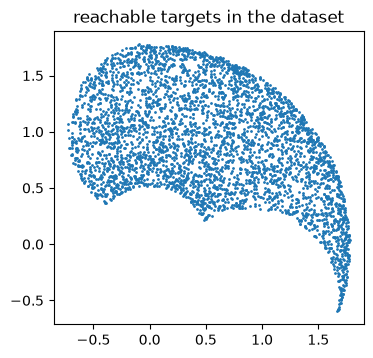

In [6]:
L1, L2 = 1.0, 0.8


def fk(q):
    """q: (N, 2) joint angles -> (N, 2) end-effector positions. Works for numpy or torch."""
    lib = torch if isinstance(q, torch.Tensor) else np
    q1, q2 = q[:, 0], q[:, 1]
    return lib.stack([L1 * lib.cos(q1) + L2 * lib.cos(q1 + q2), L1 * lib.sin(q1) + L2 * lib.sin(q1 + q2)], 1)


def other_branch(q):
    """The other IK solution reaching the same point: (q1 + 2*atan2(l2 sin q2, l1 + l2 cos q2), -q2)."""
    q1, q2 = q[:, 0], q[:, 1]
    return np.stack([q1 + 2 * np.arctan2(L2 * np.sin(q2), L1 + L2 * np.cos(q2)), -q2], 1)


rng = np.random.default_rng(0)
N = 4000
q_down = np.stack([rng.uniform(-0.5, 1.5, N), rng.uniform(0.3, 2.6, N)], 1)   # elbow-down branch
p = fk(q_down)
assert np.allclose(fk(other_branch(q_down)), p, atol=1e-9)    # both branches reach the same point

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(p[:, 0], p[:, 1], s=1)
ax.set_aspect("equal"); ax.set_title("reachable targets in the dataset")
plt.show()

## Part 3 — A two-layer MLP in NumPy with hand-written backpropagation

$\hat Y = \mathrm{ReLU}(XW_1+\mathbf b_1)W_2+\mathbf b_2$, loss $\mathcal L = \frac1B\sum_i\lVert\hat Y_i-Y_i\rVert^2$.
Backward rules (book 0.3): $\bar W = X^\top\bar Y$, $\bar X = \bar Y W^\top$, $\bar{\mathbf b}=\sum_i\bar Y_i$,
$\overline{\text{ReLU input}} = \bar H\odot\mathbb 1[Z>0]$.

In [7]:
def init_params(d_in=2, d_h=64, d_out=2, seed=0, dtype=np.float64):
    r = np.random.default_rng(seed)
    return {
        "W1": r.normal(0, math.sqrt(2 / d_in), (d_in, d_h)).astype(dtype),   # He init
        "b1": np.zeros(d_h, dtype),
        "W2": r.normal(0, math.sqrt(1 / d_h), (d_h, d_out)).astype(dtype),
        "b2": np.zeros(d_out, dtype),
    }


def forward_backward(P, X, Y):
    B = X.shape[0]
    Z1 = X @ P["W1"] + P["b1"]        # (B, d_h)
    H1 = np.maximum(Z1, 0)            # (B, d_h)
    Yh = H1 @ P["W2"] + P["b2"]       # (B, d_out)
    loss = ((Yh - Y) ** 2).sum(1).mean()
    dYh = 2 * (Yh - Y) / B            # (B, d_out)
    grads = {"W2": H1.T @ dYh, "b2": dYh.sum(0)}
    dH1 = dYh @ P["W2"].T             # (B, d_h)
    dZ1 = dH1 * (Z1 > 0)              # (B, d_h)
    grads |= {"W1": X.T @ dZ1, "b1": dZ1.sum(0)}
    return loss, grads, Yh

### 3.1 Gradient check
Central differences, float64. Relative error $< 10^{-6}$ means the backward pass is right.

In [8]:
P = init_params()
Xs, Ys = p[:16], q_down[:16]
loss, grads, _ = forward_backward(P, Xs, Ys)
eps = 1e-6
for name in ["W1", "b1", "W2", "b2"]:
    num = np.zeros_like(P[name])
    for idx in np.ndindex(P[name].shape):
        old = P[name][idx]
        P[name][idx] = old + eps; lp = forward_backward(P, Xs, Ys)[0]
        P[name][idx] = old - eps; lm = forward_backward(P, Xs, Ys)[0]
        P[name][idx] = old
        num[idx] = (lp - lm) / (2 * eps)
    rel = np.abs(num - grads[name]).max() / (np.abs(num).max() + 1e-12)
    print(f"{name}: max relative error {rel:.2e}")
    assert rel < 1e-5

W1: max relative error 4.31e-10
b1: max relative error 6.27e-10
W2: max relative error 8.62e-11
b2: max relative error 3.08e-11


### 3.2 Same numbers from PyTorch autograd

In [9]:
Pt = {k: torch.tensor(v, requires_grad=True) for k, v in P.items()}
Xt, Yt = torch.tensor(Xs), torch.tensor(Ys)
Yh_t = torch.relu(Xt @ Pt["W1"] + Pt["b1"]) @ Pt["W2"] + Pt["b2"]
loss_t = ((Yh_t - Yt) ** 2).sum(1).mean()
loss_t.backward()
print("loss numpy", loss, "torch", loss_t.item())
for k in Pt:
    print(k, "max |numpy - autograd| =", np.abs(Pt[k].grad.numpy() - grads[k]).max())
print("autograd graph:", loss_t.grad_fn, "->", loss_t.grad_fn.next_functions[0][0])

loss numpy 6.319194282504984 torch 6.319194282504985
W1 max |numpy - autograd| = 2.220446049250313e-16
b1 max |numpy - autograd| = 2.220446049250313e-16
W2 max |numpy - autograd| = 1.7763568394002505e-15
b2 max |numpy - autograd| = 0.0
autograd graph: <MeanBackward0 object at 0x7f2447f05660> -> <SumBackward1 object at 0x7f24484a94e0>


### 3.3 Train the NumPy network with minibatch SGD

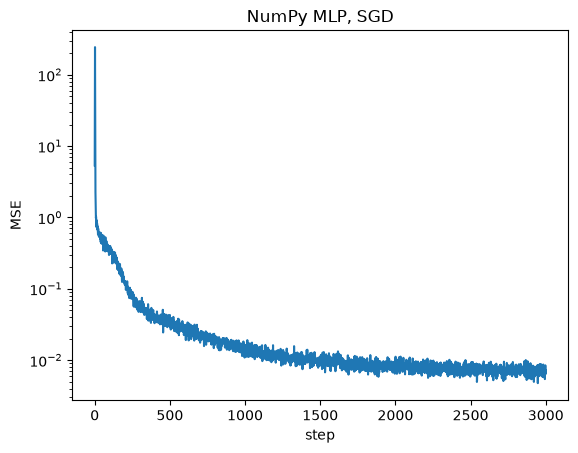

final loss 0.0073; median reaching error 3.9 cm


In [10]:
def train_numpy(X, Y, steps=3000, lr=0.05, batch=128, seed=0):
    P = init_params(seed=seed)
    r = np.random.default_rng(seed)
    hist = []
    for step in range(steps):
        idx = r.integers(0, len(X), batch)
        loss, g, _ = forward_backward(P, X[idx], Y[idx])
        for k in P:
            P[k] -= lr * g[k]
        hist.append(loss)
    return P, hist


P_np, hist_np = train_numpy(p, q_down)
plt.semilogy(hist_np); plt.xlabel("step"); plt.ylabel("MSE"); plt.title("NumPy MLP, SGD"); plt.show()


def reach_error(q_pred, p_target):
    return np.linalg.norm(fk(q_pred) - p_target, axis=1)


_, _, q_pred = forward_backward(P_np, p, q_down)
print(f"final loss {hist_np[-1]:.4f}; median reaching error {np.median(reach_error(q_pred, p)) * 100:.1f} cm")

## Part 4 — PyTorch: SGD vs Adam
The same model in `nn.Module` form, trained with the two optimisers of book section 0.3.

parameters: 4482


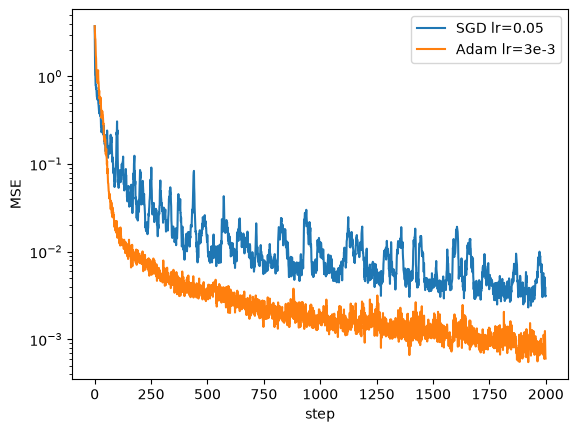

final MSE  SGD 0.0045   Adam 0.0009


In [11]:
import torch.nn as nn


def make_mlp():
    return nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2))


print("parameters:", sum(p_.numel() for p_ in make_mlp().parameters()))   # 4482, as in the book

Xtr = torch.tensor(p, dtype=torch.float32)
Ytr_single = torch.tensor(q_down, dtype=torch.float32)


def train_torch(Y, opt_name, steps=2000, lr=None, seed=0):
    set_seed(seed)
    model = make_mlp()
    opt = (torch.optim.SGD(model.parameters(), lr=lr or 0.05) if opt_name == "sgd"
           else torch.optim.Adam(model.parameters(), lr=lr or 3e-3))
    g = torch.Generator().manual_seed(seed)
    hist = []
    for _ in range(steps):
        idx = torch.randint(0, len(Xtr), (128,), generator=g)
        loss = ((model(Xtr[idx]) - Y[idx]) ** 2).sum(1).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        hist.append(loss.item())
    return model, hist


m_sgd, h_sgd = train_torch(Ytr_single, "sgd")
m_adam, h_adam = train_torch(Ytr_single, "adam")
plt.semilogy(h_sgd, label="SGD lr=0.05"); plt.semilogy(h_adam, label="Adam lr=3e-3")
plt.legend(); plt.xlabel("step"); plt.ylabel("MSE"); plt.show()
print(f"final MSE  SGD {np.mean(h_sgd[-100:]):.4f}   Adam {np.mean(h_adam[-100:]):.4f}")

## Part 5 — Regression to the mean

Now each target appears with **either** IK solution, chosen at random: the data distribution
$p(\mathbf q\mid\mathbf p)$ is bimodal. MSE is maximum likelihood under a *unimodal* Gaussian, whose
optimum is the conditional mean — the average of elbow-up and elbow-down, which reaches neither.

In [12]:
q_up = other_branch(q_down)
choose_up = rng.random(N) < 0.5
q_mixed = np.where(choose_up[:, None], q_up, q_down)
m_mixed, h_mixed = train_torch(torch.tensor(q_mixed, dtype=torch.float32), "adam", steps=3000)

with torch.no_grad():
    q_single_pred = m_adam(Xtr).numpy()
    q_mixed_pred = m_mixed(Xtr).numpy()
err_single = reach_error(q_single_pred, p)
err_mixed = reach_error(q_mixed_pred, p)
print(f"median reaching error, single-branch data: {np.median(err_single) * 100:5.1f} cm")
print(f"median reaching error, mixed-branch data:  {np.median(err_mixed) * 100:5.1f} cm")
assert np.median(err_mixed) > 5 * np.median(err_single)

median reaching error, single-branch data:   1.4 cm
median reaching error, mixed-branch data:   46.2 cm


Look at what the mixed model predicts for one target: its $q_2$ sits between the two solutions'
$+q_2$ and $-q_2$ (near 0: an almost straight arm), so the hand lands far from the target.

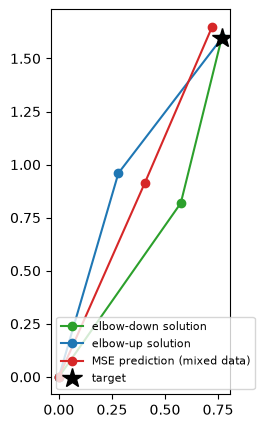

q2 down / up / predicted: 0.369 -0.369 0.01


In [13]:
def draw_arm(ax, q, **kw):
    q1, q2 = q
    j = np.array([[0, 0], [L1 * np.cos(q1), L1 * np.sin(q1)],
                  [L1 * np.cos(q1) + L2 * np.cos(q1 + q2), L1 * np.sin(q1) + L2 * np.sin(q1 + q2)]])
    ax.plot(j[:, 0], j[:, 1], "-o", **kw)


i = 7
fig, ax = plt.subplots(figsize=(5, 5))
draw_arm(ax, q_down[i], color="tab:green", label="elbow-down solution")
draw_arm(ax, q_up[i], color="tab:blue", label="elbow-up solution")
draw_arm(ax, q_mixed_pred[i], color="tab:red", label="MSE prediction (mixed data)")
ax.plot(*p[i], "k*", ms=15, label="target")
ax.set_aspect("equal"); ax.legend(loc="lower left", fontsize=8); plt.show()
print("q2 down / up / predicted:", q_down[i, 1].round(3), q_up[i, 1].round(3), q_mixed_pred[i, 1].round(3))

## Exercises

1. Replace ReLU by tanh in the NumPy network; update the backward pass ($\tanh' = 1-\tanh^2$) and re-run
   the gradient check.
2. Increase the SGD learning rate until training diverges. What is the largest stable value?
3. Fix Part 5 *without* changing the data: predict a categorical "branch" variable plus a
   regression per branch (a two-component mixture), train it with the mixture NLL (book Chapter 0
   review, exercise 4), and sample a branch at test time. Measure the reaching error.
4. Robotics: what is the analogue of the two IK branches for a drone flying around an obstacle?
   Write down the dataset that would cause the same failure.